# E-commerce Revenue & Customer Intelligence

A reproducible descriptive analysis of UCI Online Retail II. Questions: when does the retailer sell most, how do returns affect line sales, and how do repeat purchasing and customer concentration vary?

> Revenue is calculated as quantity × unit price. This is line-level sales value, not accounting revenue or profit. Returns, missing IDs, non-merchandise codes, and wholesale outliers are handled explicitly as limitations.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image
import io

DATA_PATH = Path('../data/online_retail_II.xlsx')
if not DATA_PATH.exists():
    DATA_PATH = Path('data/online_retail_II.xlsx')
if not DATA_PATH.exists():
    raise FileNotFoundError('Put the official UCI workbook at data/online_retail_II.xlsx')

sheets = pd.read_excel(DATA_PATH, sheet_name=None)
[(name, sheet.shape) for name, sheet in sheets.items()]


Out[0]: [('Year 2009-2010', (525461, 8)), ('Year 2010-2011', (541910, 8))]


[('Year 2009-2010', (525461, 8)), ('Year 2010-2011', (541910, 8))]

## Prepare the transaction rows

The workbook sheets overlap. Keep the maximum multiplicity of every exact row found in either sheet. This removes the cross-sheet overlap while preserving repeated lines within a sheet. Hashes are used as a practical row key.


In [2]:
frames = list(sheets.values())
columns = frames[0].columns.tolist()
hashes_by_sheet = [
    pd.util.hash_pandas_object(frame[columns], index=False).astype('uint64').value_counts()
    for frame in frames
]
max_repeats = pd.concat(hashes_by_sheet, axis=1).fillna(0).max(axis=1)
retail = pd.concat(frames, ignore_index=True)
retail['_row_hash'] = pd.util.hash_pandas_object(retail[columns], index=False).astype('uint64')
retail['_occurrence'] = retail.groupby('_row_hash', sort=False).cumcount()
keep = retail['_occurrence'] < retail['_row_hash'].map(max_repeats)
removed_cross_sheet = int((~keep).sum())
retail = retail.loc[keep, columns].copy()
retail['InvoiceDate'] = pd.to_datetime(retail['InvoiceDate'], errors='coerce')
retail['Invoice'] = retail['Invoice'].astype('string')
retail['IsCancellation'] = retail['Invoice'].str.startswith('C', na=False)
retail['LineRevenue'] = retail['Quantity'] * retail['Price']
print(f'Removed excess cross-sheet copies: {removed_cross_sheet:,}')
print(f'Retained transaction rows: {len(retail):,}')
retail.drop(columns=['Customer ID']).head()


Removed excess cross-sheet copies: 22,523
Retained transaction rows: 1,044,848
Out[0]: 
  Invoice StockCode  ... IsCancellation  LineRevenue
0  489434     85048  ...          False         83.4
1  489434    79323P  ...          False         81.0
2  489434    79323W  ...          False         81.0
3  489434     22041  ...          False        100.8
4  489434     21232  ...          False         30.0

[5 rows x 9 columns]


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Country,IsCancellation,LineRevenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,United Kingdom,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,United Kingdom,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,United Kingdom,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,United Kingdom,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,United Kingdom,False,30.0


## Data quality and cancellations

Rows with a missing customer ID remain usable for product and country totals, but cannot be assigned to customer cohorts or RFM segments. The UCI workbook includes returns and cancellation records; compare the cancellation invoice prefix with negative quantities before defining net sales.


In [3]:
quality = pd.DataFrame({
    'metric': ['Rows', 'Missing customer IDs', 'Missing descriptions', 'Exact within-sheet duplicates (for context)', 'Negative quantity lines', 'C-prefixed invoice lines'],
    'value': [len(retail), retail['Customer ID'].isna().sum(), retail['Description'].isna().sum(), sum(int(s.duplicated().sum()) for s in frames), (retail['Quantity'] < 0).sum(), retail['IsCancellation'].sum()]
})
quality


Out[0]: 
                                        metric    value
0                                         Rows  1044848
1                         Missing customer IDs   235287
2                         Missing descriptions     4275
3  Exact within-sheet duplicates (for context)    12133
4                      Negative quantity lines    22557
5                     C-prefixed invoice lines    19165


,metric,value
0,Rows,1044848
1,Missing customer IDs,235287
2,Missing descriptions,4275
3,Exact within-sheet duplicates (for context),12133
4,Negative quantity lines,22557
5,C-prefixed invoice lines,19165


In [4]:
retail['NegativeQuantity'] = retail['Quantity'] < 0
cancellation_check = pd.crosstab(retail['IsCancellation'], retail['NegativeQuantity'], margins=True)
cancellation_check


Out[0]: 
NegativeQuantity    False   True      All
IsCancellation                           
False             1022290   3393  1025683
True                    1  19164    19165
All               1022291  22557  1044848


NegativeQuantity,False,True,All
IsCancellation,,,
False,1022290,3393,1025683
True,1,19164,19165
All,1022291,22557,1044848


## Gross sales and returns over time

Positive quantity/price lines are counted as gross sales. Negative quantity/positive price lines are shown as returns. The net line-sales measure subtracts their absolute value; it is not a formal accounting measure.


In [5]:
positive = retail.loc[(retail['Quantity'] > 0) & (retail['Price'] > 0)].copy()
negative = retail.loc[(retail['Quantity'] < 0) & (retail['Price'] > 0)].copy()
positive['Month'] = positive['InvoiceDate'].dt.to_period('M').dt.to_timestamp()
negative['Month'] = negative['InvoiceDate'].dt.to_period('M').dt.to_timestamp()
gross = positive.groupby('Month')['LineRevenue'].sum().rename('Gross sales')
returns = (-negative.groupby('Month')['LineRevenue'].sum()).rename('Returns')
monthly = pd.concat([gross, returns], axis=1).fillna(0)
monthly['Net line sales'] = monthly['Gross sales'] - monthly['Returns']
print(f"Gross positive line sales: GBP {positive['LineRevenue'].sum():,.2f}")
print(f"Negative-quantity line value: GBP {-negative['LineRevenue'].sum():,.2f}")
print(f"Mechanical net line sales: GBP {positive['LineRevenue'].sum() + negative['LineRevenue'].sum():,.2f}")
monthly.tail()


Gross positive line sales: GBP 20,534,115.49
Negative-quantity line value: GBP 1,465,677.23
Mechanical net line sales: GBP 19,068,438.26
Out[0]: 
            Gross sales    Returns  Net line sales
Month                                             
2011-08-01   759138.380   54333.75      704804.630
2011-09-01  1058590.172   38902.55     1019687.622
2011-10-01  1154979.300   84274.63     1070704.670
2011-11-01  1509496.330   47740.08     1461756.250
2011-12-01   638810.680  205124.67      433686.010


,Gross sales,Returns,Net line sales
Month,,,
2011-08-01,759138.380,54333.75,704804.630
2011-09-01,1058590.172,38902.55,1019687.622
2011-10-01,1154979.300,84274.63,1070704.670
2011-11-01,1509496.330,47740.08,1461756.250
2011-12-01,638810.680,205124.67,433686.010


Fallback to a different backend


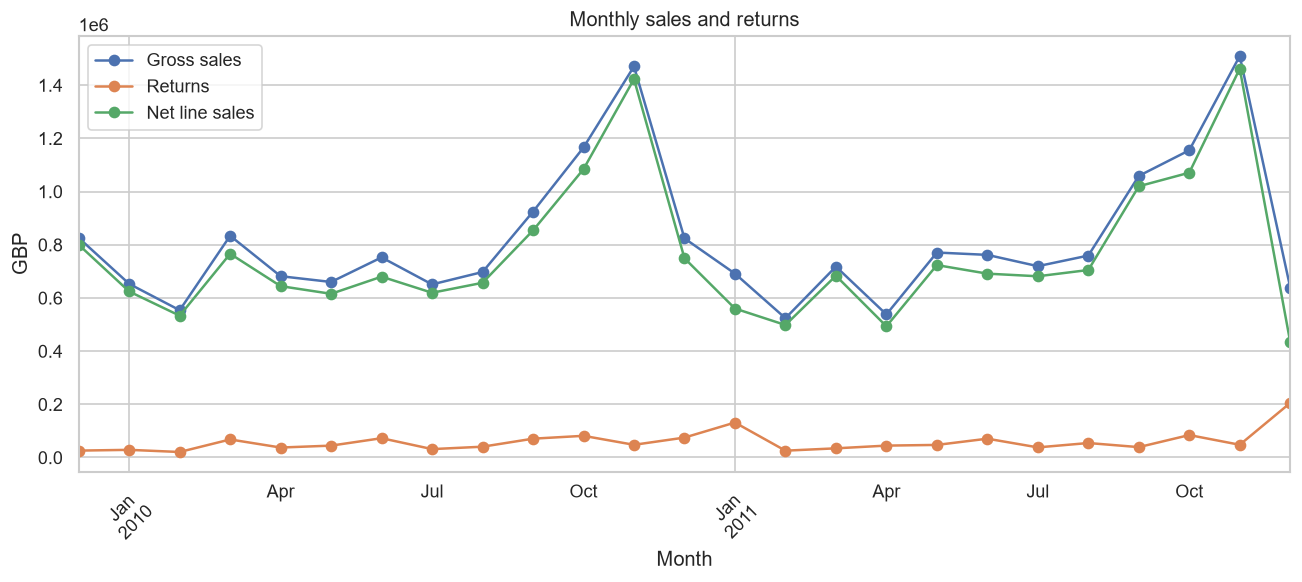

In [6]:
sns.set_theme(style='whitegrid')
ax = monthly.plot(figsize=(11, 5), marker='o')
ax.set(title='Monthly sales and returns', xlabel='Month', ylabel='GBP')
plt.xticks(rotation=45)
plt.tight_layout()
buffer = io.BytesIO()
ax.figure.savefig(buffer, format='png', dpi=120, bbox_inches='tight')
display(Image(data=buffer.getvalue()))
plt.close(ax.figure)


## Customer cohorts

A cohort is grouped by the month of the customer's first positive purchase. Retention is the share of that cohort placing at least one order in each later month. Customer IDs are missing for some transactions, so this is based only on identified buyers.


In [7]:
identified = positive.dropna(subset=['Customer ID']).copy()
identified['InvoiceMonth'] = identified['InvoiceDate'].dt.to_period('M')
customer_month = identified.groupby(['Customer ID', 'InvoiceMonth'])['Invoice'].nunique().rename('Orders').reset_index()
first_month = customer_month.groupby('Customer ID')['InvoiceMonth'].min().rename('CohortMonth')
customer_month = customer_month.join(first_month, on='Customer ID')
customer_month['CohortIndex'] = (customer_month['InvoiceMonth'].dt.year - customer_month['CohortMonth'].dt.year) * 12 + customer_month['InvoiceMonth'].dt.month - customer_month['CohortMonth'].dt.month
cohort_counts = customer_month.groupby(['CohortMonth', 'CohortIndex'])['Customer ID'].nunique().unstack(fill_value=0)
retention = cohort_counts.divide(cohort_counts.iloc[:, 0], axis=0)
month_one = retention.iloc[:, 1].dropna()
print(f'Median month-one retention: {month_one.median():.1%} across {len(month_one)} eligible cohorts')


Median month-one retention: 20.4% across 25 eligible cohorts


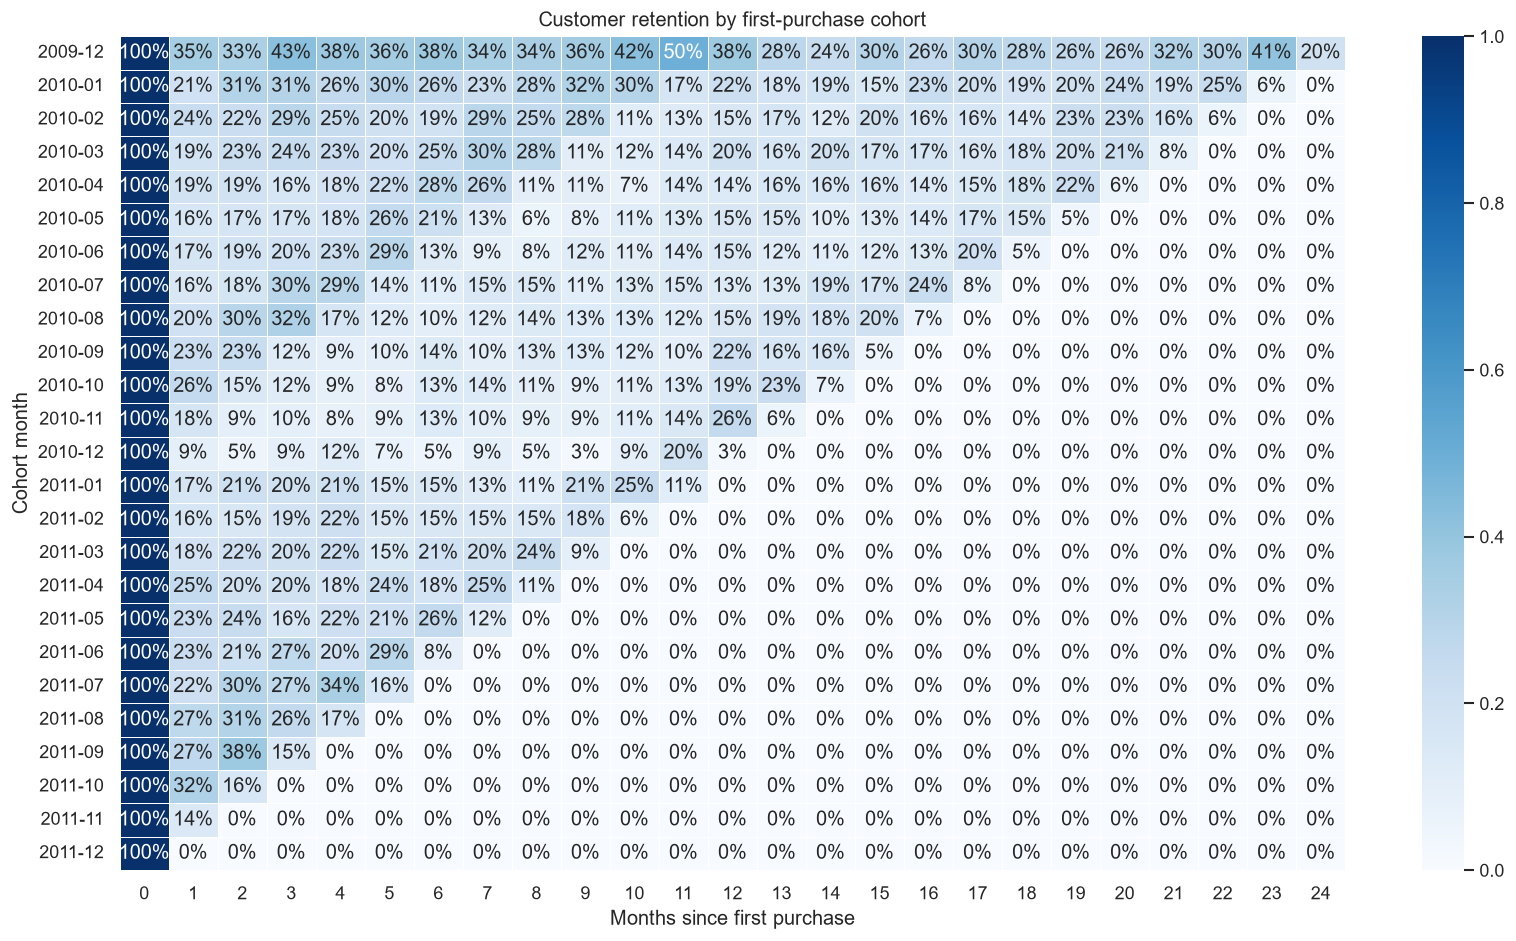

In [8]:
fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(retention, mask=retention.isna(), cmap='Blues', vmin=0, vmax=1, annot=True, fmt='.0%', linewidths=.3, ax=ax)
ax.set(title='Customer retention by first-purchase cohort', xlabel='Months since first purchase', ylabel='Cohort month')
plt.tight_layout()
buffer = io.BytesIO()
ax.figure.savefig(buffer, format='png', dpi=120, bbox_inches='tight')
display(Image(data=buffer.getvalue()))
plt.close(ax.figure)


## Market mix and product caveats

The raw stock-code list includes postage and manual adjustments, so rankings below are transaction-code rankings rather than a clean merchandise catalog. Review special codes and exceptional bulk orders before drawing product recommendations.


In [9]:
positive['RevenueGBP'] = positive['Quantity'] * positive['Price']
country = positive.groupby('Country').agg(RevenueGBP=('RevenueGBP', 'sum'), Invoices=('Invoice', 'nunique')).sort_values('RevenueGBP', ascending=False)
print(f"Leading country share: {country.iloc[0].name} — {country.iloc[0].RevenueGBP / country.RevenueGBP.sum():.1%}")
country.head(10)


Leading country share: United Kingdom — 85.1%
Out[0]: 
                  RevenueGBP  Invoices
Country                               
United Kingdom  1.746627e+07     36536
EIRE            6.591490e+05       626
Netherlands     5.540397e+05       228
Germany         4.255784e+05       789
France          3.506542e+05       622
Australia       1.693510e+05        95
Spain           1.083838e+05       154
Switzerland     1.007079e+05        93
Sweden          9.190372e+04       105
Denmark         6.858069e+04        43


,RevenueGBP,Invoices
Country,,
United Kingdom,1.746627e+07,36536
EIRE,6.591490e+05,626
Netherlands,5.540397e+05,228
Germany,4.255784e+05,789
France,3.506542e+05,622
Australia,1.693510e+05,95
Spain,1.083838e+05,154
Switzerland,1.007079e+05,93
Sweden,9.190372e+04,105


In [10]:
products = positive.groupby(['StockCode', 'Description'], dropna=False).agg(RevenueGBP=('RevenueGBP', 'sum'), Units=('Quantity', 'sum'), Invoices=('Invoice', 'nunique')).sort_values('RevenueGBP', ascending=False)
products.head(15)


Out[0]: 
                                               RevenueGBP  Units  Invoices
StockCode Description                                                     
M         Manual                                339988.46   9932       785
22423     REGENCY CAKESTAND 3 TIER              331084.27  26519      3918
DOT       DOTCOM POSTAGE                        309854.11   1415      1415
85123A    WHITE HANGING HEART T-LIGHT HOLDER    257887.40  94262      5356
23843     PAPER CRAFT , LITTLE BIRDIE           168469.60  80995         1
47566     PARTY BUNTING                         148395.98  28216      2674
85099B    JUMBO BAG RED RETROSPOT               146257.12  77442      3245
84879     ASSORTED COLOUR BIRD ORNAMENT         129681.08  80293      2807
POST      POSTAGE                               125682.42   5363      1851
22086     PAPER CHAIN KIT 50'S CHRISTMAS        117884.19  35126      2018
23166     MEDIUM CERAMIC TOP STORAGE JAR         81700.92  78033       247
79321     CHILLI

,,RevenueGBP,Units,Invoices
StockCode,Description,,,
M,Manual,339988.46,9932,785
22423,REGENCY CAKESTAND 3 TIER,331084.27,26519,3918
DOT,DOTCOM POSTAGE,309854.11,1415,1415
85123A,WHITE HANGING HEART T-LIGHT HOLDER,257887.40,94262,5356
23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
47566,PARTY BUNTING,148395.98,28216,2674
85099B,JUMBO BAG RED RETROSPOT,146257.12,77442,3245
84879,ASSORTED COLOUR BIRD ORNAMENT,129681.08,80293,2807
POST,POSTAGE,125682.42,5363,1851


## Exploratory customer segments (RFM)

Recency, frequency, and monetary values are ranked into dataset-relative quartiles. Segment labels are heuristics for exploration, not predictions of future value.


In [11]:
snapshot = positive['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)
rfm = identified.groupby('Customer ID').agg(
    RecencyDays=('InvoiceDate', lambda s: (snapshot - s.max().normalize()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('LineRevenue', 'sum'),
)
rfm['R'] = pd.qcut(rfm['RecencyDays'].rank(method='first', ascending=False), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['M'] = pd.qcut(rfm['Monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['RFMScore'] = rfm[['R', 'F', 'M']].sum(axis=1)
def assign_segment(row):
    if row.RFMScore >= 10: return 'Champions'
    if row.R >= 3 and row.F >= 3: return 'Loyal'
    if row.R >= 3 and row.F <= 2: return 'New / potential'
    if row.R <= 2 and row.F >= 3: return 'At risk'
    return 'Needs attention'
rfm['Segment'] = rfm.apply(assign_segment, axis=1)
segment_summary = rfm.groupby('Segment').agg(Customers=('RecencyDays', 'size'), RevenueGBP=('Monetary', 'sum'), MedianFrequency=('Frequency', 'median'))
segment_summary['CustomerShare'] = segment_summary['Customers'] / segment_summary['Customers'].sum()
segment_summary['RevenueShare'] = segment_summary['RevenueGBP'] / segment_summary['RevenueGBP'].sum()
segment_summary.sort_values('RevenueGBP', ascending=False)


Out[0]: 
                 Customers    RevenueGBP  ...  CustomerShare  RevenueShare
Segment                                   ...                             
Champions             1731  1.404080e+07  ...       0.294488      0.805482
At risk                756  1.229006e+06  ...       0.128615      0.070505
Needs attention       2051  1.126138e+06  ...       0.348928      0.064603
New / potential        879  5.679099e+05  ...       0.149541      0.032579
Loyal                  461  4.676966e+05  ...       0.078428      0.026830

[5 rows x 5 columns]


,Customers,RevenueGBP,MedianFrequency,CustomerShare,RevenueShare
Segment,,,,,
Champions,1731,1.404080e+07,10.0,0.294488,0.805482
At risk,756,1.229006e+06,5.0,0.128615,0.070505
Needs attention,2051,1.126138e+06,1.0,0.348928,0.064603
New / potential,879,5.679099e+05,2.0,0.149541,0.032579
Loyal,461,4.676966e+05,4.0,0.078428,0.026830


## Interpretation and limitations

- November is the strongest full month in both years observed; Dec 2011 is partial and should not be compared as a full month.
- UK transactions dominate the recorded line sales. The top 10% of identified customers account for about 64% of their gross sales.
- The data contain missing customer IDs, special stock codes, cancellation/quantity mismatches, and a one-invoice item-volume outlier.
- There are no cost, margin, marketing-channel, or inventory data. Treat all recommendations as hypotheses to validate, not causal conclusions.

For the reproducible full set of CSVs and charts, run `python src/analyze_retail.py` from the project root.
